# Friedman-Style Gradient Boosting → Modern Boosting
## California Housing — Complete Three-Experiment Research Notebook

This is the complete analysis version of the study. It contains the experiment setup, raw per-seed results, all major summary tables, model-selection tables, test comparisons, plots, reproducibility information, and a result-driven research-insight section.

### Experiments

**A. Manual Friedman-style gradient boosting** — LS, LAD, Huber; J = 2, 3, 6, 11, 21.

**B. Manual implementation vs scikit-learn GradientBoostingRegressor** — J = 6 and the same three losses.

**C. Modern systems** — HistGradientBoostingRegressor, XGBoost, and LightGBM.

The test set is kept separate from model selection. Final seeds are 101–103.


## Experimental rules

- Primary selection metric: **validation MAE**
- Final metrics: test MAE, test RMSE, test R², and test MAE relative to a constant-median baseline
- Same 60/20/20 split for every model within each seed
- Final seeds: **101, 102, 103**
- The previously explored seed-42 result is not reused as the final test result
- No feature scaling or model-specific feature engineering
- CPU training
- Record package versions and runtime information
- Modern-system search is deliberately small and fixed rather than exhaustive


## Run order / time-saving note

Run cells from top to bottom once for a fresh study.

The expensive cells are:
1. **Experiment A2 tree-size search** — 90 manual configurations across five seeds.
2. **Experiment C modern validation search** — 90 model/configuration/seed combinations.

If you already completed a long-running experiment in the older notebook and its result dataframe is still available in the same kernel, **do not rerun that expensive cell unnecessarily**. Continue from the next section and run the final-table/insight cells.

The notebook keeps raw per-seed result tables so the mean, standard deviation, selected iteration, and boundary behavior can all be inspected rather than reporting only one aggregate number.

In [ ]:

!pip -q install xgboost lightgbm


In [2]:

import os, sys, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor

import sklearn
import xgboost as xgb
import lightgbm as lgb

warnings.filterwarnings("ignore")

SEEDS = [101, 102, 103]
LEARNING_RATE = 0.1
MAX_ESTIMATORS = 3000
TREE_SIZES = [2, 3, 6, 11, 21]
HUBER_ALPHA = 0.9
THREADS = 2

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgb.__version__)
print("lightgbm:", lgb.__version__)


Python: 3.13.2
Platform: Windows-11-10.0.26200-SP0
scikit-learn: 1.9.1
xgboost: 3.4.1
lightgbm: 4.7.0



## 1. California Housing

California Housing is the only dataset used in this notebook.


In [3]:

housing = fetch_california_housing(as_frame=True)
X = housing.data.copy()
y = housing.target.to_numpy(dtype=float)

print("Samples:", len(y))
print("Features:", X.shape[1])
print("Feature names:", list(X.columns))
display(X.head())


Samples: 20640
Features: 8
Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [4]:

def make_split(X, y, seed):
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.40, random_state=seed
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=seed
    )
    return X_train, X_val, X_test, y_train, y_val, y_test

def median_baseline_mae(y_train, y_eval):
    pred = np.full(len(y_eval), np.median(y_train))
    return mean_absolute_error(y_eval, pred)

baseline_rows = []
for seed in SEEDS:
    Xtr, Xv, Xte, ytr, yv, yte = make_split(X, y, seed)
    baseline_rows.append({
        "seed": seed,
        "train_n": len(ytr),
        "validation_n": len(yv),
        "test_n": len(yte),
        "validation_baseline_MAE": median_baseline_mae(ytr, yv),
        "test_baseline_MAE": median_baseline_mae(ytr, yte)
    })

baseline_df = pd.DataFrame(baseline_rows)
display(baseline_df)


,seed,train_n,validation_n,test_n,validation_baseline_MAE,test_baseline_MAE
0,101,12384,4128,4128,0.892611,0.880954
1,102,12384,4128,4128,0.891994,0.874502
2,103,12384,4128,4128,0.875227,0.878567



# Experiment A — Manual Friedman-style Gradient Boosting

For every boosting step:

1. Start with a training-target initial prediction.
2. Compute training residuals `y - F(x)`.
3. Compute the loss-specific pseudo-response.
4. Fit a squared-error regression tree with at most J leaves.
5. Calculate the loss-specific leaf correction from the original residuals.
6. Update by `learning_rate × correction`.
7. Score validation MAE.
8. Repeat through 3,000 steps.

For Huber, delta is recomputed at every iteration as the chosen 90th percentile of the absolute training residuals.


In [5]:

def initial_prediction(y_train, loss):
    if loss == "LS":
        return float(np.mean(y_train))
    if loss in ("LAD", "Huber"):
        return float(np.median(y_train))
    raise ValueError(loss)

def pseudo_response(residuals, loss, delta=None):
    if loss == "LS":
        return residuals.copy()
    if loss == "LAD":
        return np.sign(residuals)
    if loss == "Huber":
        return np.clip(residuals, -delta, delta)
    raise ValueError(loss)

def leaf_corrections(residuals, leaf_ids, loss, delta=None):
    corrections = np.zeros(len(residuals), dtype=float)
    for leaf in np.unique(leaf_ids):
        mask = leaf_ids == leaf
        r = residuals[mask]

        if loss == "LS":
            gamma = np.mean(r)
        elif loss == "LAD":
            gamma = np.median(r)
        elif loss == "Huber":
            med = np.median(r)
            gamma = med + np.mean(np.clip(r - med, -delta, delta))
        else:
            raise ValueError(loss)

        corrections[mask] = gamma
    return corrections

def manual_boosting(
    X_train, y_train, X_val, y_val,
    loss, n_leaves, learning_rate=0.1,
    max_estimators=3000, huber_alpha=0.9, random_state=42
):
    X_train = np.asarray(X_train)
    X_val = np.asarray(X_val)
    y_train = np.asarray(y_train, dtype=float)
    y_val = np.asarray(y_val, dtype=float)

    init = initial_prediction(y_train, loss)
    F_train = np.full(len(y_train), init, dtype=float)
    F_val = np.full(len(y_val), init, dtype=float)

    train_history, val_history = [], []

    for m in range(1, max_estimators + 1):
        residuals = y_train - F_train

        if loss == "Huber":
            delta = float(np.quantile(np.abs(residuals), huber_alpha))
            delta = max(delta, np.finfo(float).eps)
        else:
            delta = None

        pseudo = pseudo_response(residuals, loss, delta)

        tree = DecisionTreeRegressor(
            criterion="squared_error",
            max_leaf_nodes=n_leaves,
            max_depth=None,
            min_samples_leaf=1,
            random_state=random_state + m
        )
        tree.fit(X_train, pseudo)

        train_leaf = tree.apply(X_train)
        val_leaf = tree.apply(X_val)

        train_gamma = leaf_corrections(residuals, train_leaf, loss, delta)

        leaf_map = {}
        for leaf in np.unique(train_leaf):
            leaf_map[leaf] = train_gamma[train_leaf == leaf][0]

        val_gamma = np.array([leaf_map.get(v, 0.0) for v in val_leaf])

        F_train += learning_rate * train_gamma
        F_val += learning_rate * val_gamma

        train_history.append(mean_absolute_error(y_train, F_train))
        val_history.append(mean_absolute_error(y_val, F_val))

    best_idx = int(np.argmin(val_history))
    return {
        "best_iteration": best_idx + 1,
        "best_val_mae": float(val_history[best_idx]),
        "train_history": np.array(train_history),
        "val_history": np.array(val_history)
    }


## Experiment A1 — Loss comparison at J = 6

In [6]:

loss_results = []
loss_histories = {}

for seed in SEEDS:
    Xtr, Xv, Xte, ytr, yv, yte = make_split(X, y, seed)
    for loss in ["LS", "LAD", "Huber"]:
        r = manual_boosting(
            Xtr, ytr, Xv, yv,
            loss=loss, n_leaves=6,
            learning_rate=LEARNING_RATE,
            max_estimators=MAX_ESTIMATORS,
            huber_alpha=HUBER_ALPHA,
            random_state=seed
        )
        loss_results.append({
            "seed": seed, "loss": loss, "J": 6,
            "best_iteration": r["best_iteration"],
            "validation_MAE": r["best_val_mae"]
        })
        loss_histories[(seed, loss)] = r["val_history"]

loss_results_df = pd.DataFrame(loss_results)
display(loss_results_df)

display(
    loss_results_df.groupby("loss")["validation_MAE"]
    .agg(["mean", "std"]).sort_values("mean")
)


,seed,loss,J,best_iteration,validation_MAE
0,101,LS,6,2990,0.305984
1,101,LAD,6,2986,0.318699
2,101,Huber,6,2703,0.303842
3,102,LS,6,2736,0.299450
4,102,LAD,6,2997,0.311297
5,102,Huber,6,2935,0.296141
6,103,LS,6,2948,0.298726
7,103,LAD,6,2886,0.304859
8,103,Huber,6,2703,0.294185


,mean,std
loss,,
Huber,0.298056,0.005105
LS,0.301386,0.003998
LAD,0.311618,0.006926


### Validation MAE by boosting step

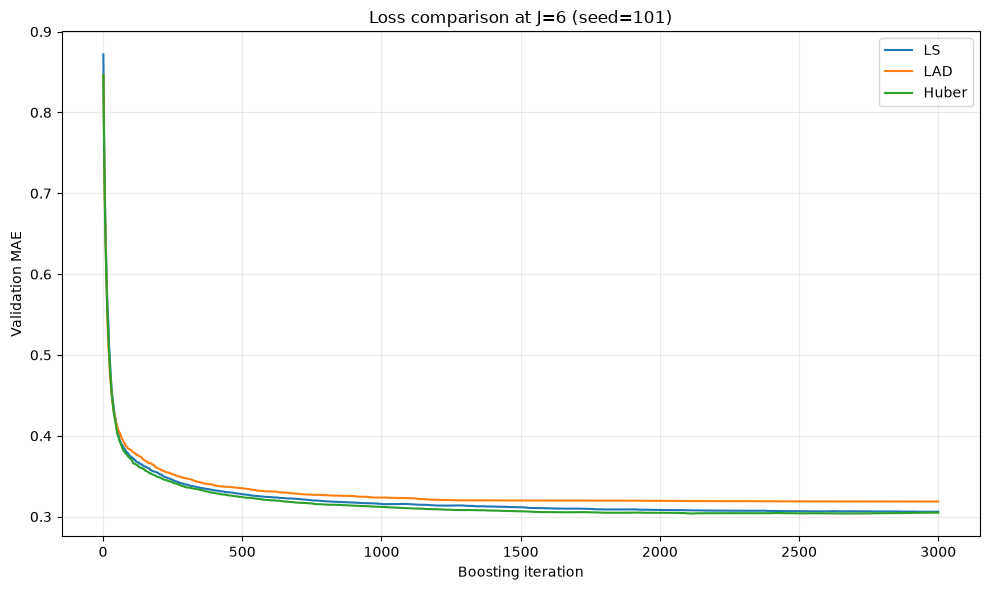

In [7]:

seed_plot = SEEDS[0]
plt.figure(figsize=(10, 6))
for loss in ["LS", "LAD", "Huber"]:
    plt.plot(
        np.arange(1, MAX_ESTIMATORS + 1),
        loss_histories[(seed_plot, loss)],
        label=loss
    )
plt.xlabel("Boosting iteration")
plt.ylabel("Validation MAE")
plt.title(f"Loss comparison at J=6 (seed={seed_plot})")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## Experiment A2 — Tree-size comparison

In [8]:

tree_results = []
tree_histories = {}

for seed in SEEDS:
    Xtr, Xv, Xte, ytr, yv, yte = make_split(X, y, seed)

    for loss in ["LS", "LAD", "Huber"]:
        for J in TREE_SIZES:
            r = manual_boosting(
                Xtr, ytr, Xv, yv,
                loss=loss, n_leaves=J,
                learning_rate=LEARNING_RATE,
                max_estimators=MAX_ESTIMATORS,
                huber_alpha=HUBER_ALPHA,
                random_state=seed
            )
            tree_results.append({
                "seed": seed, "loss": loss, "J": J,
                "best_iteration": r["best_iteration"],
                "validation_MAE": r["best_val_mae"]
            })
            tree_histories[(seed, loss, J)] = r["val_history"]

tree_results_df = pd.DataFrame(tree_results)
display(tree_results_df)


,seed,loss,J,best_iteration,validation_MAE
0,101,LS,2,3000,0.406192
1,101,LS,3,2933,0.327203
2,101,LS,6,2990,0.305984
3,101,LS,11,2668,0.304182
4,101,LS,21,1016,0.300464
5,101,LAD,2,2935,0.403730
6,101,LAD,3,2994,0.339471
7,101,LAD,6,2986,0.318699
8,101,LAD,11,2947,0.316859
9,101,LAD,21,2999,0.309892


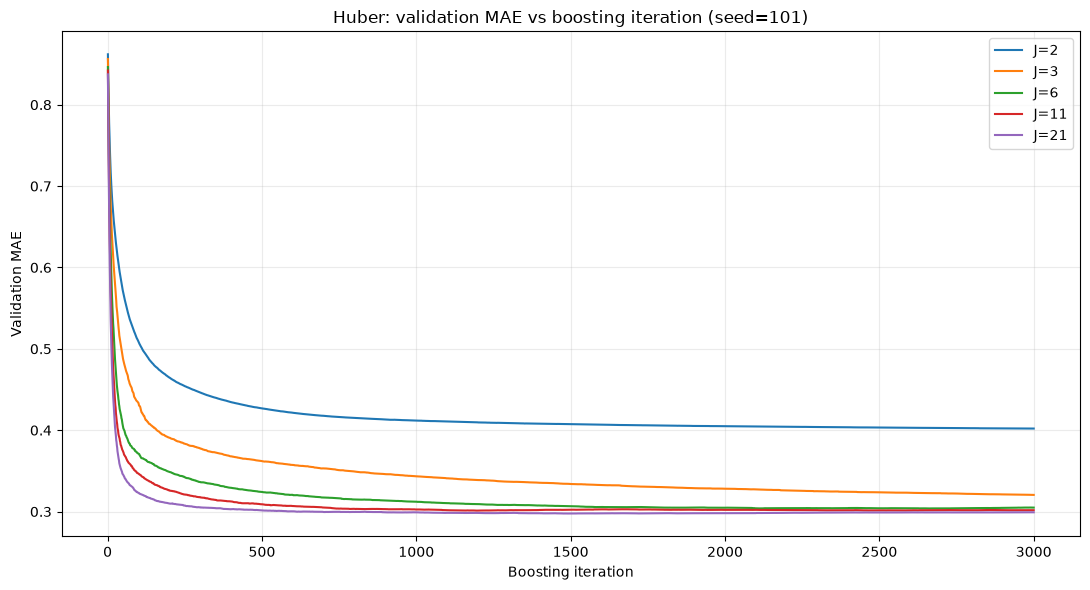

In [9]:

# Huber validation curves by tree size
plt.figure(figsize=(11, 6))
for J in TREE_SIZES:
    plt.plot(
        np.arange(1, MAX_ESTIMATORS + 1),
        tree_histories[(SEEDS[0], "Huber", J)],
        label=f"J={J}"
    )
plt.xlabel("Boosting iteration")
plt.ylabel("Validation MAE")
plt.title(f"Huber: validation MAE vs boosting iteration (seed={SEEDS[0]})")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


,loss,J,mean_validation_MAE,std_validation_MAE,mean_best_iteration,std_best_iteration,min_best_iteration,max_best_iteration,hit_3000
0,Huber,2,0.392524,0.008401,2996.000000,2.645751,2993,2998,False
1,Huber,3,0.315167,0.005426,2999.333333,1.154701,2998,3000,True
2,Huber,6,0.298056,0.005105,2780.333333,133.945262,2703,2935,False
3,Huber,11,0.295470,0.005007,1352.333333,168.054555,1199,1532,False
4,Huber,21,0.293039,0.004571,1122.000000,327.481297,924,1500,False
5,LAD,2,0.394409,0.008225,2977.666667,36.963946,2935,3000,True
6,LAD,3,0.329215,0.009783,2998.000000,3.464102,2994,3000,True
7,LAD,6,0.311618,0.006926,2956.333333,61.158265,2886,2997,False
8,LAD,11,0.308073,0.007955,2713.000000,448.404951,2196,2996,False
9,LAD,21,0.304638,0.006507,2512.333333,746.384173,1653,2999,False


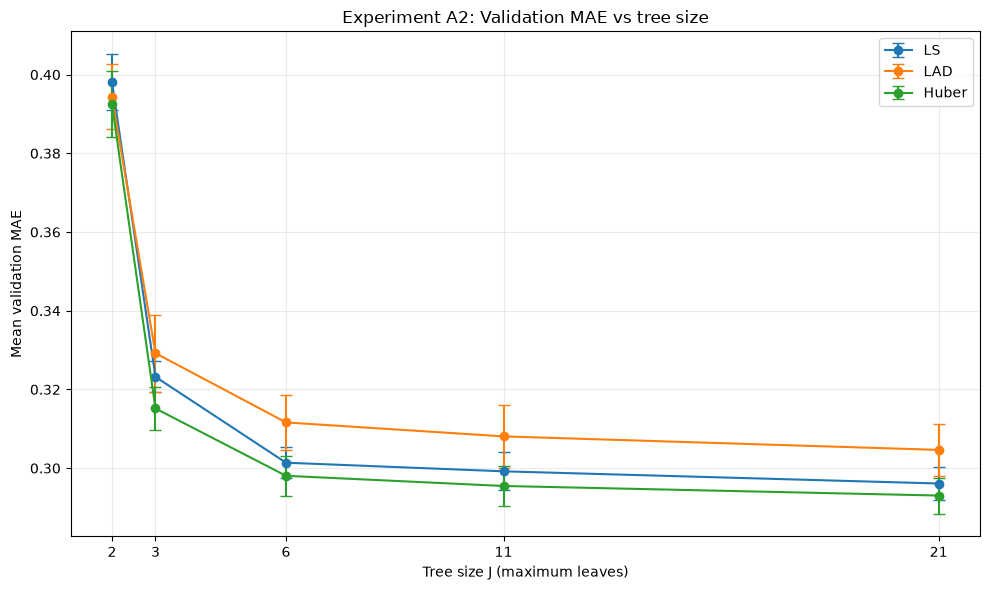

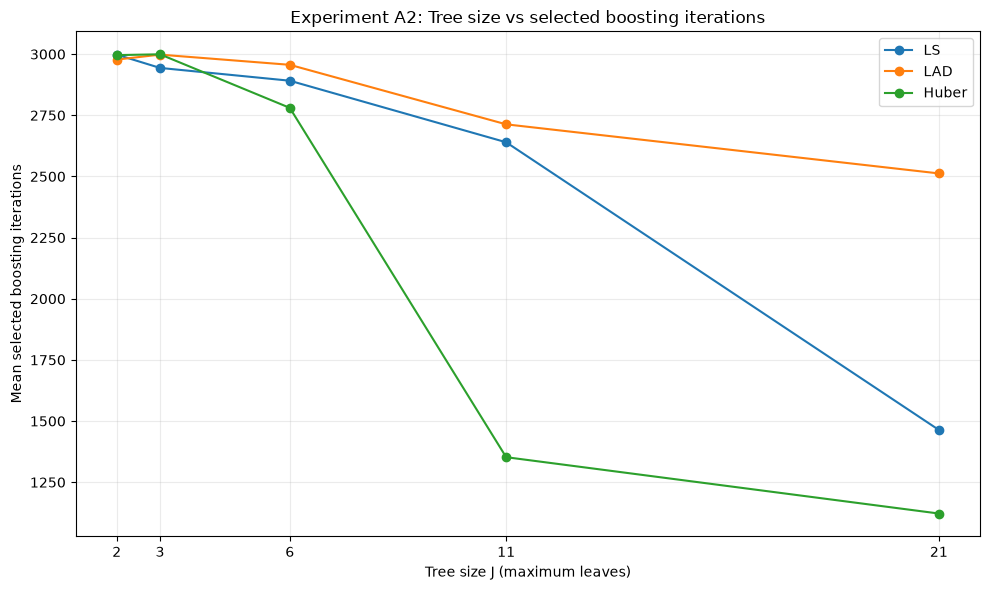

In [10]:
# Complete Experiment A2 summary: error, iterations, and iteration-budget boundary.
summary_tree = (
    tree_results_df.groupby(["loss", "J"])
    .agg(
        mean_validation_MAE=("validation_MAE", "mean"),
        std_validation_MAE=("validation_MAE", "std"),
        mean_best_iteration=("best_iteration", "mean"),
        std_best_iteration=("best_iteration", "std"),
        min_best_iteration=("best_iteration", "min"),
        max_best_iteration=("best_iteration", "max")
    )
    .reset_index()
)

summary_tree["hit_3000"] = summary_tree["max_best_iteration"] >= MAX_ESTIMATORS

display(summary_tree)

# Validation MAE by tree size.
plt.figure(figsize=(10, 6))
for loss in ["LS", "LAD", "Huber"]:
    d = summary_tree[summary_tree["loss"] == loss]
    plt.errorbar(
        d["J"], d["mean_validation_MAE"],
        yerr=d["std_validation_MAE"],
        marker="o", capsize=4, label=loss
    )
plt.xlabel("Tree size J (maximum leaves)")
plt.ylabel("Mean validation MAE")
plt.title("Experiment A2: Validation MAE vs tree size")
plt.xticks(TREE_SIZES)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Selected iterations by tree size.
plt.figure(figsize=(10, 6))
for loss in ["LS", "LAD", "Huber"]:
    d = summary_tree[summary_tree["loss"] == loss]
    plt.plot(d["J"], d["mean_best_iteration"], marker="o", label=loss)
plt.xlabel("Tree size J (maximum leaves)")
plt.ylabel("Mean selected boosting iterations")
plt.title("Experiment A2: Tree size vs selected boosting iterations")
plt.xticks(TREE_SIZES)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## Experiment A3 — Final test evaluation

For each seed, choose the loss/tree-size/iteration combination using validation MAE only.

Then refit the selected manual model on training + validation data and evaluate once on the held-out test set.


In [11]:

def fit_manual_fixed(
    X_train, y_train, X_eval,
    loss, n_leaves, n_estimators,
    learning_rate=0.1, huber_alpha=0.9, random_state=42
):
    X_train = np.asarray(X_train)
    X_eval = np.asarray(X_eval)
    y_train = np.asarray(y_train, dtype=float)

    init = initial_prediction(y_train, loss)
    F_train = np.full(len(y_train), init, dtype=float)
    F_eval = np.full(len(X_eval), init, dtype=float)

    for m in range(1, n_estimators + 1):
        residuals = y_train - F_train

        if loss == "Huber":
            delta = float(np.quantile(np.abs(residuals), huber_alpha))
            delta = max(delta, np.finfo(float).eps)
        else:
            delta = None

        pseudo = pseudo_response(residuals, loss, delta)

        tree = DecisionTreeRegressor(
            criterion="squared_error",
            max_leaf_nodes=n_leaves,
            max_depth=None,
            min_samples_leaf=1,
            random_state=random_state + m
        )
        tree.fit(X_train, pseudo)

        train_leaf = tree.apply(X_train)
        eval_leaf = tree.apply(X_eval)

        gamma = leaf_corrections(residuals, train_leaf, loss, delta)

        leaf_map = {
            leaf: gamma[train_leaf == leaf][0]
            for leaf in np.unique(train_leaf)
        }
        eval_gamma = np.array([leaf_map.get(v, 0.0) for v in eval_leaf])

        F_train += learning_rate * gamma
        F_eval += learning_rate * eval_gamma

    return F_eval

selected_manual = []

for seed in SEEDS:
    d = tree_results_df[tree_results_df["seed"] == seed]
    best = d.loc[d["validation_MAE"].idxmin()]

    Xtr, Xv, Xte, ytr, yv, yte = make_split(X, y, seed)
    Xtv = pd.concat([Xtr, Xv], axis=0)
    ytv = np.concatenate([ytr, yv])

    pred = fit_manual_fixed(
        Xtv, ytv, Xte,
        loss=best["loss"],
        n_leaves=int(best["J"]),
        n_estimators=int(best["best_iteration"]),
        learning_rate=LEARNING_RATE,
        huber_alpha=HUBER_ALPHA,
        random_state=seed
    )

    test_mae = mean_absolute_error(yte, pred)
    baseline = median_baseline_mae(ytv, yte)

    selected_manual.append({
        "seed": seed,
        "loss": best["loss"],
        "J": int(best["J"]),
        "best_iteration": int(best["best_iteration"]),
        "validation_MAE": float(best["validation_MAE"]),
        "test_MAE": test_mae,
        "test_RMSE": np.sqrt(mean_squared_error(yte, pred)),
        "test_R2": r2_score(yte, pred),
        "test_MAE_relative_to_baseline": test_mae / baseline
    })

selected_manual_df = pd.DataFrame(selected_manual)
display(selected_manual_df)


,seed,loss,J,best_iteration,validation_MAE,test_MAE,test_RMSE,test_R2,test_MAE_relative_to_baseline
0,101,Huber,21,1500,0.297601,0.293332,0.458695,0.842180,0.332962
1,102,Huber,21,924,0.293056,0.289292,0.452927,0.842108,0.330807
2,103,Huber,21,942,0.288460,0.295759,0.461189,0.839910,0.336631



# Experiment B — Manual implementation vs sklearn GradientBoostingRegressor

This is an implementation comparison. The models are not expected to produce bit-for-bit identical predictions because tree construction and implementation details can differ.


In [12]:

gbd_results = []

for seed in SEEDS:
    Xtr, Xv, Xte, ytr, yv, yte = make_split(X, y, seed)

    for loss in ["LS", "LAD", "Huber"]:
        sklearn_loss = {
            "LS": "squared_error",
            "LAD": "absolute_error",
            "Huber": "huber"
        }[loss]

        model = GradientBoostingRegressor(
            loss=sklearn_loss,
            learning_rate=LEARNING_RATE,
            n_estimators=MAX_ESTIMATORS,
            max_leaf_nodes=6,
            max_depth=None,
            min_samples_leaf=1,
            alpha=HUBER_ALPHA,
            random_state=seed
        )

        t0 = time.perf_counter()
        model.fit(Xtr, ytr)
        _ = time.perf_counter() - t0

        best_mae = np.inf
        best_iter = None
        for i, pred_v in enumerate(model.staged_predict(Xv), start=1):
            mae = mean_absolute_error(yv, pred_v)
            if mae < best_mae:
                best_mae = mae
                best_iter = i

        Xtv = pd.concat([Xtr, Xv], axis=0)
        ytv = np.concatenate([ytr, yv])

        final_model = GradientBoostingRegressor(
            loss=sklearn_loss,
            learning_rate=LEARNING_RATE,
            n_estimators=best_iter,
            max_leaf_nodes=6,
            max_depth=None,
            min_samples_leaf=1,
            alpha=HUBER_ALPHA,
            random_state=seed
        )

        t0 = time.perf_counter()
        final_model.fit(Xtv, ytv)
        final_time = time.perf_counter() - t0

        pred = final_model.predict(Xte)
        test_mae = mean_absolute_error(yte, pred)

        gbd_results.append({
            "seed": seed,
            "loss": loss,
            "J": 6,
            "best_iteration": best_iter,
            "validation_MAE": best_mae,
            "test_MAE": test_mae,
            "test_RMSE": np.sqrt(mean_squared_error(yte, pred)),
            "test_R2": r2_score(yte, pred),
            "test_MAE_relative_to_baseline": test_mae / median_baseline_mae(ytv, yte),
            "training_time_seconds": final_time
        })

gbd_results_df = pd.DataFrame(gbd_results)
display(gbd_results_df)


,seed,loss,J,best_iteration,validation_MAE,test_MAE,test_RMSE,test_R2,test_MAE_relative_to_baseline,training_time_seconds
0,101,LS,6,2990,0.305916,0.306669,0.469778,0.834462,0.348102,63.506725
1,101,LAD,6,2865,0.321271,0.315058,0.492638,0.817959,0.357624,87.061429
2,101,Huber,6,2955,0.301379,0.299552,0.463288,0.839004,0.340023,70.315523
3,102,LS,6,2733,0.299428,0.297178,0.459160,0.837733,0.339825,59.024839
4,102,LAD,6,2829,0.310729,0.307995,0.487360,0.817189,0.352194,90.441392
5,102,Huber,6,2993,0.296214,0.290675,0.454589,0.840948,0.332389,72.983986
6,103,LS,6,2948,0.298413,0.303431,0.461364,0.839789,0.345364,63.773971
7,103,LAD,6,3000,0.303744,0.312140,0.490675,0.818785,0.355276,88.813040
8,103,Huber,6,2723,0.296614,0.296898,0.462742,0.838830,0.337927,65.578004



# Experiment C — Modern boosting systems

Controlled benchmark:

- HistGradientBoostingRegressor
- XGBoost
- LightGBM
- squared-error regression
- learning rate: 0.03 or 0.1
- maximum leaves: 15, 31, 63
- maximum steps: 3,000
- validation MAE selects the configuration

The leaf limits make capacity approximately comparable, but the algorithms are not identical.


In [13]:

MODERN_LR = [0.03, 0.1]
MODERN_LEAVES = [15, 31, 63]
MODERN_MAX_ESTIMATORS = 3000
EARLY_STOP_PATIENCE = 100


In [14]:

modern_validation_rows = []

for seed in SEEDS:
    Xtr, Xv, Xte, ytr, yv, yte = make_split(X, y, seed)

    for lr in MODERN_LR:
        for leaves in MODERN_LEAVES:

            # HistGradientBoosting
            hist = HistGradientBoostingRegressor(
                loss="squared_error",
                learning_rate=lr,
                max_iter=MODERN_MAX_ESTIMATORS,
                max_leaf_nodes=leaves,
                early_stopping=False,
                random_state=seed
            )
            t0 = time.perf_counter()
            hist.fit(Xtr, ytr)
            hist_fit_time = time.perf_counter() - t0

            best_mae = np.inf
            best_iter = None
            no_improve = 0

            for i, pv in enumerate(hist.staged_predict(Xv), start=1):
                mae = mean_absolute_error(yv, pv)
                if mae < best_mae:
                    best_mae, best_iter, no_improve = mae, i, 0
                else:
                    no_improve += 1
                if no_improve >= EARLY_STOP_PATIENCE:
                    break

            modern_validation_rows.append({
                "seed": seed, "model": "HistGB",
                "learning_rate": lr, "max_leaves": leaves,
                "best_iteration": best_iter,
                "validation_MAE": best_mae
            })

            # XGBoost
            xgb_model = xgb.XGBRegressor(
                objective="reg:squarederror",
                eval_metric="mae",
                learning_rate=lr,
                n_estimators=MODERN_MAX_ESTIMATORS,
                max_leaves=leaves,
                max_depth=0,
                tree_method="hist",
                subsample=1.0,
                colsample_bytree=1.0,
                n_jobs=THREADS,
                random_state=seed,
                verbosity=0
            )
            xgb_model.fit(Xtr, ytr, eval_set=[(Xv, yv)], verbose=False)
            eval_mae = xgb_model.evals_result()["validation_0"]["mae"]
            best_iter = int(np.argmin(eval_mae)) + 1
            best_mae = float(np.min(eval_mae))

            modern_validation_rows.append({
                "seed": seed, "model": "XGBoost",
                "learning_rate": lr, "max_leaves": leaves,
                "best_iteration": best_iter,
                "validation_MAE": best_mae
            })

            # LightGBM
            lgb_model = lgb.LGBMRegressor(
                objective="regression",
                learning_rate=lr,
                n_estimators=MODERN_MAX_ESTIMATORS,
                num_leaves=leaves,
                max_depth=-1,
                min_child_samples=20,
                subsample=1.0,
                colsample_bytree=1.0,
                n_jobs=THREADS,
                random_state=seed,
                verbosity=-1
            )
            lgb_model.fit(
                Xtr, ytr,
                eval_set=[(Xv, yv)],
                eval_metric="l1",
                callbacks=[lgb.early_stopping(EARLY_STOP_PATIENCE, verbose=False)]
            )
            best_iter = int(lgb_model.best_iteration_)
            pred_v = lgb_model.predict(Xv, num_iteration=best_iter)
            best_mae = mean_absolute_error(yv, pred_v)

            modern_validation_rows.append({
                "seed": seed, "model": "LightGBM",
                "learning_rate": lr, "max_leaves": leaves,
                "best_iteration": best_iter,
                "validation_MAE": best_mae
            })

modern_validation_df = pd.DataFrame(modern_validation_rows)
display(modern_validation_df)


,seed,model,learning_rate,max_leaves,best_iteration,validation_MAE
0,101,HistGB,0.03,15,2997,0.296511
1,101,XGBoost,0.03,15,2992,0.302103
2,101,LightGBM,0.03,15,2998,0.296627
3,101,HistGB,0.03,31,2819,0.291857
4,101,XGBoost,0.03,31,2974,0.296476
5,101,LightGBM,0.03,31,2105,0.291750
6,101,HistGB,0.03,63,1018,0.292877
7,101,XGBoost,0.03,63,2499,0.299518
8,101,LightGBM,0.03,63,1684,0.292378
9,101,HistGB,0.10,15,1303,0.295459



## Final test evaluation for Experiment C

Select the best configuration from the validation results for each seed/model. Then refit on training + validation and evaluate once on test.


In [15]:

modern_final_rows = []

for seed in SEEDS:
    Xtr, Xv, Xte, ytr, yv, yte = make_split(X, y, seed)
    Xtv = pd.concat([Xtr, Xv], axis=0)
    ytv = np.concatenate([ytr, yv])

    for kind in ["HistGB", "XGBoost", "LightGBM"]:
        candidates = modern_validation_df[
            (modern_validation_df.seed == seed) &
            (modern_validation_df.model == kind)
        ]
        best = candidates.loc[candidates.validation_MAE.idxmin()]

        lr = float(best.learning_rate)
        leaves = int(best.max_leaves)
        n_estimators = int(best.best_iteration)

        if kind == "HistGB":
            model = HistGradientBoostingRegressor(
                loss="squared_error",
                learning_rate=lr,
                max_iter=n_estimators,
                max_leaf_nodes=leaves,
                early_stopping=False,
                random_state=seed
            )
        elif kind == "XGBoost":
            model = xgb.XGBRegressor(
                objective="reg:squarederror",
                eval_metric="mae",
                learning_rate=lr,
                n_estimators=n_estimators,
                max_leaves=leaves,
                max_depth=0,
                tree_method="hist",
                subsample=1.0,
                colsample_bytree=1.0,
                n_jobs=THREADS,
                random_state=seed,
                verbosity=0
            )
        else:
            model = lgb.LGBMRegressor(
                objective="regression",
                learning_rate=lr,
                n_estimators=n_estimators,
                num_leaves=leaves,
                max_depth=-1,
                min_child_samples=20,
                subsample=1.0,
                colsample_bytree=1.0,
                n_jobs=THREADS,
                random_state=seed,
                verbosity=-1
            )

        t0 = time.perf_counter()
        model.fit(Xtv, ytv)
        fit_time = time.perf_counter() - t0

        pred = model.predict(Xte)
        test_mae = mean_absolute_error(yte, pred)

        modern_final_rows.append({
            "seed": seed,
            "model": kind,
            "learning_rate": lr,
            "max_leaves": leaves,
            "best_iteration": n_estimators,
            "validation_MAE": float(best.validation_MAE),
            "test_MAE": test_mae,
            "test_RMSE": np.sqrt(mean_squared_error(yte, pred)),
            "test_R2": r2_score(yte, pred),
            "test_MAE_relative_to_baseline": test_mae / median_baseline_mae(ytv, yte),
            "training_time_seconds": fit_time
        })

modern_final_df = pd.DataFrame(modern_final_rows)
display(modern_final_df)


,seed,model,learning_rate,max_leaves,best_iteration,validation_MAE,test_MAE,test_RMSE,test_R2,test_MAE_relative_to_baseline,training_time_seconds
0,101,HistGB,0.03,31,2819,0.291857,0.293564,0.457101,0.843276,0.333226,3.614923
1,101,XGBoost,0.03,31,2974,0.296476,0.293541,0.457738,0.842838,0.333200,3.028211
2,101,LightGBM,0.03,31,2105,0.291750,0.294214,0.457886,0.842737,0.333964,1.364396
3,102,HistGB,0.03,63,836,0.291011,0.287687,0.449054,0.844797,0.328971,2.085771
4,102,XGBoost,0.03,63,2011,0.293296,0.288212,0.448096,0.845459,0.329572,3.508128
5,102,LightGBM,0.03,63,788,0.292038,0.287206,0.447070,0.846165,0.328421,0.888292
6,103,HistGB,0.03,31,1521,0.287533,0.293096,0.454591,0.844458,0.333600,1.928573
7,103,XGBoost,0.03,31,2963,0.287559,0.294408,0.457629,0.842372,0.335093,2.912184
8,103,LightGBM,0.03,31,2034,0.285577,0.291786,0.450915,0.846963,0.332109,1.273397


# Final tables and plots

## Optional Experiment A4 — Test metrics for every loss × tree-size configuration

The primary protocol selects the model using validation MAE and then evaluates the selected model on the held-out test set. The cell below is included when a **complete loss × J test table** is desired for reporting.

It requires additional manual refits, so it is intentionally separate from the main selection workflow. Do not use these test values for model selection.

In [16]:
manual_all_config_test_rows = []

for seed in SEEDS:
    Xtr, Xv, Xte, ytr, yv, yte = make_split(X, y, seed)
    Xtv = pd.concat([Xtr, Xv], axis=0)
    ytv = np.concatenate([ytr, yv])

    seed_tree = tree_results_df[tree_results_df["seed"] == seed]

    for _, selected in seed_tree.iterrows():
        pred = fit_manual_fixed(
            Xtv, ytv, Xte,
            loss=selected["loss"],
            n_leaves=int(selected["J"]),
            n_estimators=int(selected["best_iteration"]),
            learning_rate=LEARNING_RATE,
            huber_alpha=HUBER_ALPHA,
            random_state=seed
        )

        test_mae = mean_absolute_error(yte, pred)
        baseline = median_baseline_mae(ytv, yte)

        manual_all_config_test_rows.append({
            "seed": seed,
            "loss": selected["loss"],
            "J": int(selected["J"]),
            "best_iteration": int(selected["best_iteration"]),
            "validation_MAE": float(selected["validation_MAE"]),
            "test_MAE": test_mae,
            "test_RMSE": np.sqrt(mean_squared_error(yte, pred)),
            "test_R2": r2_score(yte, pred),
            "test_MAE_relative_to_baseline": test_mae / baseline
        })

manual_all_config_test_df = pd.DataFrame(manual_all_config_test_rows)

display(manual_all_config_test_df)

manual_all_config_summary = (
    manual_all_config_test_df
    .groupby(["loss", "J"])
    [["validation_MAE", "test_MAE", "test_RMSE", "test_R2", "test_MAE_relative_to_baseline"]]
    .agg(["mean", "std"])
)

display(manual_all_config_summary)

,seed,loss,J,best_iteration,validation_MAE,test_MAE,test_RMSE,test_R2,test_MAE_relative_to_baseline
0,101,LS,2,3000,0.406192,0.403255,0.567336,0.758569,0.457737
1,101,LS,3,2933,0.327203,0.329154,0.486662,0.822349,0.373625
2,101,LS,6,2990,0.305984,0.307333,0.471338,0.833361,0.348855
3,101,LS,11,2668,0.304182,0.302321,0.465848,0.837220,0.343166
4,101,LS,21,1016,0.300464,0.297404,0.454794,0.844853,0.337585
5,101,LAD,2,2935,0.403730,0.400777,0.592466,0.736706,0.454924
6,101,LAD,3,2994,0.339471,0.330829,0.512530,0.802962,0.375526
7,101,LAD,6,2986,0.318699,0.312855,0.488667,0.820882,0.355123
8,101,LAD,11,2947,0.316859,0.312302,0.486977,0.822119,0.354496
9,101,LAD,21,2999,0.309892,0.309626,0.481309,0.826236,0.351458


validation_MAE            test_MAE           test_RMSE            \
                   mean       std      mean       std      mean       std   
loss  J                                                                     
Huber 2        0.392524  0.008401  0.394647  0.005467  0.569327  0.005168   
      3        0.315167  0.005426  0.319318  0.004163  0.486916  0.002990   
      6        0.298056  0.005105  0.295565  0.003995  0.460459  0.002568   
      11       0.295470  0.005007  0.294719  0.006289  0.459274  0.006543   
      21       0.293039  0.004571  0.292794  0.003267  0.457604  0.004238   
LAD   2        0.394409  0.008225  0.394797  0.006673  0.586742  0.005716   
      3        0.329215  0.009783  0.329590  0.003050  0.511448  0.002186   
      6        0.311618  0.006926  0.310651  0.003294  0.487489  0.002591   
      11       0.308073  0.007955  0.307310  0.005459  0.481839  0.006480   
      21       0.304638  0.006507  0.305683  0.005896  0.477691  0.007186   
LS    2        0.398105  0.007057  0.399618  0.005161  0.564798  0.006179   
      3        0.323203  0.003928  0.326483  0.005667  0.484617  0.006986   
      6        0.301386  0.003998  0.302923  0.004823  0.464438  0.006081   
      11       0.299195  0.004804  0.299740  0.004577  0.462212  0.005706   
      21       0.296098  0.004300  0.295778  0.004569  0.454178  0.005230   

           test_R2           test_MAE_relative_to_baseline            
              mean       std                          mean       std  
loss  J                                                               
Huber 2   0.754504  0.001172                      0.449461  0.004599  
      3   0.820427  0.000779                      0.363672  0.003607  
      6   0.839408  0.001267                      0.336618  0.003321  
      11  0.840244  0.002335                      0.335650  0.006083  
      21  0.841400  0.001290                      0.333467  0.002945  
LAD   2   0.739253  0.002236                      0.449629  0.005930  
      3   0.801873  0.001163                      0.375374  0.002386  
      6   0.820003  0.000801                      0.353802  0.002516  
      11  0.824160  0.002309                      0.349991  0.004917  
      21  0.827174  0.002877                      0.348137  0.005490  
LS    2   0.758396  0.002260                      0.455125  0.004259  
      3   0.822123  0.002994                      0.371828  0.005272  
      6   0.836621  0.003000                      0.344995  0.004211  
      11  0.838193  0.001750                      0.341372  0.004072  
      21  0.843765  0.002071                      0.336862  0.004222

In [17]:
# ================================================================
# FINAL RESULTS DASHBOARD — ALL IMPORTANT TABLES
# ================================================================

print("TABLE 1 — Dataset / baseline by seed")
display(baseline_df)

print("TABLE 2 — Experiment A1: manual loss comparison at J=6, every seed")
display(loss_results_df.sort_values(["loss", "seed"]))

print("TABLE 3 — Experiment A1: loss mean ± std")
loss_summary = (
    loss_results_df.groupby("loss")["validation_MAE"]
    .agg(["mean", "std", "min", "max"])
    .sort_values("mean")
)
display(loss_summary)

print("TABLE 4 — Experiment A2: complete tree-size summary")
display(summary_tree)

print("TABLE 5 — Experiment A2: validation MAE matrix")
tree_mae_matrix = summary_tree.pivot(index="loss", columns="J", values="mean_validation_MAE")
display(tree_mae_matrix)

print("TABLE 6 — Experiment A2: selected-iteration matrix")
tree_iter_matrix = summary_tree.pivot(index="loss", columns="J", values="mean_best_iteration")
display(tree_iter_matrix)

print("TABLE 7 — Experiment A3: selected manual model on held-out test")
display(selected_manual_df)

print("TABLE 8 — Experiment A3: selected manual model mean ± std")
manual_summary = selected_manual_df.groupby(["loss", "J"])[
    ["validation_MAE", "test_MAE", "test_RMSE", "test_R2", "test_MAE_relative_to_baseline"]
].agg(["mean", "std"])
display(manual_summary)

print("TABLE 9 — Experiment B: sklearn GradientBoostingRegressor, every seed")
display(gbd_results_df)

print("TABLE 10 — Experiment B: sklearn mean ± std")
sklearn_summary = gbd_results_df.groupby("loss")[
    ["validation_MAE", "test_MAE", "test_RMSE", "test_R2", "training_time_seconds"]
].agg(["mean", "std"])
display(sklearn_summary)

print("TABLE 11 — Experiment B: manual vs sklearn validation comparison")
implementation_comparison = (
    loss_results_df.groupby("loss")["validation_MAE"].mean().rename("manual_mean_val_MAE")
    .to_frame()
    .join(gbd_results_df.groupby("loss")["validation_MAE"].mean().rename("sklearn_mean_val_MAE"))
)
implementation_comparison["sklearn_minus_manual"] = (
    implementation_comparison["sklearn_mean_val_MAE"] - implementation_comparison["manual_mean_val_MAE"]
)
display(implementation_comparison)

print("TABLE 12 — Experiment C: complete modern validation search")
modern_search_summary = (
    modern_validation_df.groupby(["model", "learning_rate", "max_leaves"])
    .agg(
        mean_validation_MAE=("validation_MAE", "mean"),
        std_validation_MAE=("validation_MAE", "std"),
        mean_best_iteration=("best_iteration", "mean"),
        std_best_iteration=("best_iteration", "std")
    )
    .reset_index()
    .sort_values(["model", "mean_validation_MAE"])
)
display(modern_search_summary)

print("TABLE 13 — Experiment C: best modern configuration by mean validation MAE")
modern_best_configs = (
    modern_search_summary.sort_values("mean_validation_MAE")
    .groupby("model", as_index=False).first()
)
display(modern_best_configs)

print("TABLE 14 — Experiment C: every seed held-out test result")
display(modern_final_df.sort_values(["model", "seed"]))

print("TABLE 15 — Experiment C: modern systems mean ± std")
modern_summary = modern_final_df.groupby("model")[
    ["test_MAE", "test_RMSE", "test_R2", "test_MAE_relative_to_baseline", "training_time_seconds"]
].agg(["mean", "std"])
display(modern_summary)

print("TABLE 16 — Modern ranking by mean test MAE")
modern_ranking = (
    modern_final_df.groupby("model")
    .agg(
        mean_test_MAE=("test_MAE", "mean"),
        std_test_MAE=("test_MAE", "std"),
        mean_test_RMSE=("test_RMSE", "mean"),
        mean_test_R2=("test_R2", "mean"),
        mean_training_time_seconds=("training_time_seconds", "mean")
    )
    .sort_values("mean_test_MAE")
    .reset_index()
)
display(modern_ranking)

TABLE 1 — Dataset / baseline by seed


,seed,train_n,validation_n,test_n,validation_baseline_MAE,test_baseline_MAE
0,101,12384,4128,4128,0.892611,0.880954
1,102,12384,4128,4128,0.891994,0.874502
2,103,12384,4128,4128,0.875227,0.878567


TABLE 2 — Experiment A1: manual loss comparison at J=6, every seed


,seed,loss,J,best_iteration,validation_MAE
2,101,Huber,6,2703,0.303842
5,102,Huber,6,2935,0.296141
8,103,Huber,6,2703,0.294185
1,101,LAD,6,2986,0.318699
4,102,LAD,6,2997,0.311297
7,103,LAD,6,2886,0.304859
0,101,LS,6,2990,0.305984
3,102,LS,6,2736,0.299450
6,103,LS,6,2948,0.298726


TABLE 3 — Experiment A1: loss mean ± std


...

,seed,model,learning_rate,max_leaves,best_iteration,validation_MAE,test_MAE,test_RMSE,test_R2,test_MAE_relative_to_baseline,training_time_seconds
0,101,HistGB,0.03,31,2819,0.291857,0.293564,0.457101,0.843276,0.333226,3.614923
3,102,HistGB,0.03,63,836,0.291011,0.287687,0.449054,0.844797,0.328971,2.085771
6,103,HistGB,0.03,31,1521,0.287533,0.293096,0.454591,0.844458,0.333600,1.928573
2,101,LightGBM,0.03,31,2105,0.291750,0.294214,0.457886,0.842737,0.333964,1.364396
5,102,LightGBM,0.03,63,788,0.292038,0.287206,0.447070,0.846165,0.328421,0.888292
8,103,LightGBM,0.03,31,2034,0.285577,0.291786,0.450915,0.846963,0.332109,1.273397
1,101,XGBoost,0.03,31,2974,0.296476,0.293541,0.457738,0.842838,0.333200,3.028211
4,102,XGBoost,0.03,63,2011,0.293296,0.288212,0.448096,0.845459,0.329572,3.508128
7,103,XGBoost,0.03,31,2963,0.287559,0.294408,0.457629,0.842372,0.335093,2.912184


TABLE 15 — Experiment C: modern systems mean ± std


test_MAE           test_RMSE             test_R2            \
              mean       std      mean       std      mean       std   
model                                                                  
HistGB    0.291449  0.003267  0.453582  0.004117  0.844177  0.000799   
LightGBM  0.291069  0.003559  0.451957  0.005483  0.845289  0.002246   
XGBoost   0.292054  0.003355  0.454488  0.005536  0.843556  0.001664   

         test_MAE_relative_to_baseline           training_time_seconds  \
                                  mean       std                  mean   
model                                                                    
HistGB                        0.331932  0.002571              2.543089   
LightGBM                      0.331498  0.002821              1.175362   
XGBoost                       0.332622  0.002805              3.149507   

                    
               std  
model               
HistGB    0.931557  
LightGBM  0.252739  
XGBoost   0.315946

TABLE 16 — Modern ranking by mean test MAE


,model,mean_test_MAE,std_test_MAE,mean_test_RMSE,mean_test_R2,mean_training_time_seconds
0,LightGBM,0.291069,0.003559,0.451957,0.845289,1.175362
1,HistGB,0.291449,0.003267,0.453582,0.844177,2.543089
2,XGBoost,0.292054,0.003355,0.454488,0.843556,3.149507


## 5. One-page comparison table

This table is intended to make the final model comparison easy to copy into the report. It compares the selected manual model, sklearn GBDR, and the three modern systems using the same test metrics where applicable.

In [18]:
manual_one = selected_manual_df.groupby("loss").agg(
    test_MAE=("test_MAE", "mean"),
    test_RMSE=("test_RMSE", "mean"),
    test_R2=("test_R2", "mean"),
    test_MAE_relative_to_baseline=("test_MAE_relative_to_baseline", "mean")
).reset_index().assign(category="Manual selected")
manual_one = manual_one.rename(columns={"loss":"model"})

sk_one = gbd_results_df.groupby("loss").agg(
    test_MAE=("test_MAE", "mean"),
    test_RMSE=("test_RMSE", "mean"),
    test_R2=("test_R2", "mean"),
    test_MAE_relative_to_baseline=("test_MAE_relative_to_baseline", "mean")
).reset_index().assign(category="sklearn GBDR")
sk_one = sk_one.rename(columns={"loss":"model"})

modern_one = modern_final_df.groupby("model").agg(
    test_MAE=("test_MAE", "mean"),
    test_RMSE=("test_RMSE", "mean"),
    test_R2=("test_R2", "mean"),
    test_MAE_relative_to_baseline=("test_MAE_relative_to_baseline", "mean")
).reset_index().assign(category="Modern system")

comparison_one_page = pd.concat([
    manual_one[["category","model","test_MAE","test_RMSE","test_R2","test_MAE_relative_to_baseline"]],
    sk_one[["category","model","test_MAE","test_RMSE","test_R2","test_MAE_relative_to_baseline"]],
    modern_one[["category","model","test_MAE","test_RMSE","test_R2","test_MAE_relative_to_baseline"]]
], ignore_index=True)

comparison_one_page = comparison_one_page.sort_values("test_MAE")
display(comparison_one_page)

,category,model,test_MAE,test_RMSE,test_R2,test_MAE_relative_to_baseline
5,Modern system,LightGBM,0.291069,0.451957,0.845289,0.331498
4,Modern system,HistGB,0.291449,0.453582,0.844177,0.331932
6,Modern system,XGBoost,0.292054,0.454488,0.843556,0.332622
0,Manual selected,Huber,0.292794,0.457604,0.841400,0.333467
1,sklearn GBDR,Huber,0.295708,0.460206,0.839594,0.336780
3,sklearn GBDR,LS,0.302426,0.463434,0.837328,0.344430
2,sklearn GBDR,LAD,0.311731,0.490224,0.817978,0.355031


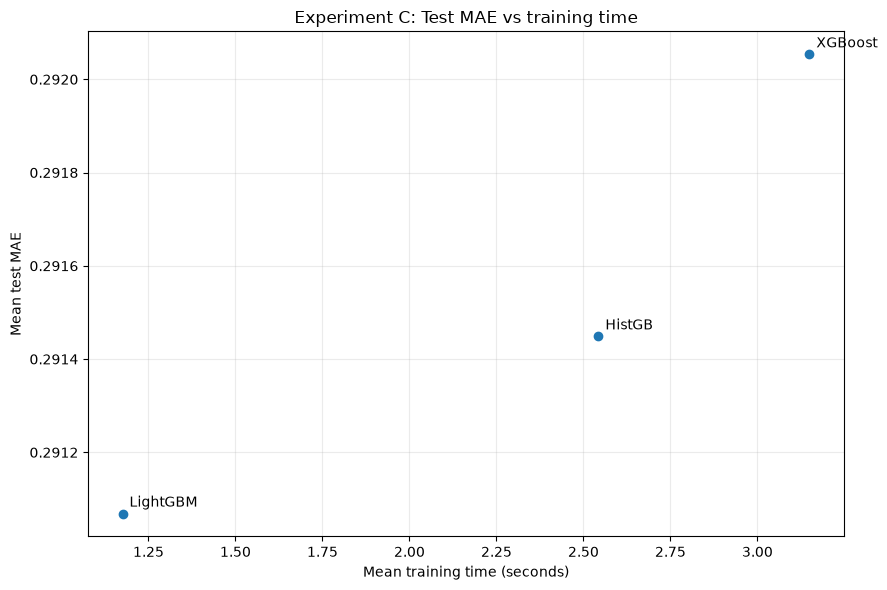

In [19]:

# Test MAE versus training time.
d = (
    modern_final_df.groupby("model")
    .agg(test_MAE=("test_MAE", "mean"),
         training_time_seconds=("training_time_seconds", "mean"))
    .reset_index()
)

plt.figure(figsize=(9, 6))
plt.scatter(d.training_time_seconds, d.test_MAE)

for _, r in d.iterrows():
    plt.annotate(
        r.model,
        (r.training_time_seconds, r.test_MAE),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Mean training time (seconds)")
plt.ylabel("Mean test MAE")
plt.title("Experiment C: Test MAE vs training time")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()



# Interpretation checklist

Do not write conclusions before the notebook has run.

Answer from the measured results:

### Experiment A
- Which loss performs best at J=6?
- How does best validation MAE change with J?
- Do smaller trees require more boosting iterations?
- Does any configuration hit the 3,000-step boundary?

### Experiment B
- Are the manual and sklearn implementations broadly consistent?
- Where do their results differ?
- Are differences implementation-level rather than evidence of a different learning objective?

### Experiment C
- Which system has the lowest test MAE?
- Which is fastest in this Colab runtime?
- Is there a meaningful accuracy/efficiency trade-off?
- How large are the differences relative to variation across seeds?

## Scope limitation

This is a controlled California Housing case study. It does not establish a universal ranking of boosting algorithms.

CatBoost and NGBoost belong in the literature review rather than this point-prediction benchmark because their important contributions address different capabilities: categorical/ordered boosting for CatBoost and probabilistic prediction for NGBoost.


## 11. Research insights — calculated only from measured results

This section is intentionally written as a **result-extraction tool**, not a source of pre-written conclusions. Run it after all experiments finish.

It reports:
- best loss at J=6;
- best tested tree size for each loss;
- change from the smallest to largest tested tree;
- selected iteration trend;
- whether any configuration reaches the 3,000-step boundary;
- manual vs sklearn differences;
- modern-system accuracy and efficiency ranking;
- seed-to-seed variability.

Use these outputs when writing the paper. Do not replace measured values with assumptions.

In [20]:
# ------------------------- Experiment A -------------------------
best_loss_j6 = loss_summary.sort_values("mean").iloc[0]

best_J_by_loss = (
    summary_tree.sort_values("mean_validation_MAE")
    .groupby("loss", as_index=False).first()
)

small_J = min(TREE_SIZES)
large_J = max(TREE_SIZES)
small_large = summary_tree[summary_tree["J"].isin([small_J, large_J])].pivot(
    index="loss", columns="J", values="mean_validation_MAE"
)

iteration_trend = (
    summary_tree.groupby("J")["mean_best_iteration"]
    .mean().reset_index()
)

budget_hits = summary_tree[summary_tree["hit_3000"]]

print("A1 — Best loss at J=6")
print(f"Loss: {best_loss_j6.name if hasattr(best_loss_j6, 'name') else best_loss_j6['loss']}")
print(f"Mean validation MAE: {best_loss_j6['mean']:.6f}")

print("\nA2 — Best tested J for each loss")
display(best_J_by_loss[["loss", "J", "mean_validation_MAE", "mean_best_iteration"]])

print(f"A2 — Mean validation MAE at J={small_J} vs J={large_J}")
display(small_large)

print("A2 — Mean selected iterations by J")
display(iteration_trend)

print("A2 — Configurations whose best iteration reached the 3,000-step budget")
if len(budget_hits):
    display(budget_hits)
else:
    print("None")

# ------------------------- Experiment B -------------------------
implementation = implementation_comparison.copy()
implementation["absolute_difference"] = implementation["sklearn_minus_manual"].abs()

print("\nB — Manual vs sklearn validation comparison")
display(implementation)

# ------------------------- Experiment C -------------------------
modern_ranking = modern_ranking.copy()
fastest_model = modern_ranking.loc[modern_ranking["mean_training_time_seconds"].idxmin(), "model"]
best_accuracy_model = modern_ranking.iloc[0]["model"]

print("\nC — Modern systems")
print("Lowest mean test MAE:", best_accuracy_model)
print("Fastest mean final fit:", fastest_model)
display(modern_ranking)

print("\nC — Accuracy variation across seeds")
seed_variation = modern_final_df.groupby("model")["test_MAE"].agg(["mean", "std", "min", "max"])
display(seed_variation)

print("\nIMPORTANT: These are measured findings for this California Housing protocol, not universal claims.")

A1 — Best loss at J=6
Loss: Huber
Mean validation MAE: 0.298056

A2 — Best tested J for each loss


,loss,J,mean_validation_MAE,mean_best_iteration
0,Huber,21,0.293039,1122.000000
1,LAD,21,0.304638,2512.333333
2,LS,21,0.296098,1463.666667


A2 — Mean validation MAE at J=2 vs J=21


J,2,21
loss,,
Huber,0.392524,0.293039
LAD,0.394409,0.304638
LS,0.398105,0.296098


A2 — Mean selected iterations by J


...


C — Modern systems
Lowest mean test MAE: LightGBM
Fastest mean final fit: LightGBM


,model,mean_test_MAE,std_test_MAE,mean_test_RMSE,mean_test_R2,mean_training_time_seconds
0,LightGBM,0.291069,0.003559,0.451957,0.845289,1.175362
1,HistGB,0.291449,0.003267,0.453582,0.844177,2.543089
2,XGBoost,0.292054,0.003355,0.454488,0.843556,3.149507



C — Accuracy variation across seeds


,mean,std,min,max
model,,,,
HistGB,0.291449,0.003267,0.287687,0.293564
LightGBM,0.291069,0.003559,0.287206,0.294214
XGBoost,0.292054,0.003355,0.288212,0.294408



IMPORTANT: These are measured findings for this California Housing protocol, not universal claims.



# Reproducibility record

The following cell records the software environment used for the run. Include its output with the final report.


In [21]:

print("Python:", sys.version)
print("Platform:", platform.platform())
print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgb.__version__)
print("lightgbm:", lgb.__version__)
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("Seeds:", SEEDS)
print("Threads:", THREADS)


Python: 3.13.2 (tags/v3.13.2:4f8bb39, Feb  4 2025, 15:23:48) [MSC v.1942 64 bit (AMD64)]
Platform: Windows-11-10.0.26200-SP0
scikit-learn: 1.9.1
xgboost: 3.4.1
lightgbm: 4.7.0
numpy: 2.5.4
pandas: 3.0.6
Seeds: [101, 102, 103]
Threads: 2
